In [54]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# TASK 1 - Data Transformation

## Import Libraries

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from transformations import center_and_scale, drop_boolean
import unicodedata
import datetime

In [56]:
def normalize_text(text):
    text = unicodedata.normalize('NFD', text)
    text = ''.join(char for char in text if unicodedata.category(char) != 'Mn')
    return text

In [57]:
df_merged = pd.read_csv('../dataset/merged.csv', skipinitialspace=True)
df_merged.head()

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,...,delta,time,birth_year,weight,height,nationality,id_race,name_race,id_cyclist,name_cyclist
0,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,0,sean-kelly,...,0.0,04:02:24,1956.0,77.0,180.0,Ireland,tour-de-france/1978/stage-6,Tour de France,sean-kelly,Sean Kelly
1,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,1,gerrie-knetemann,...,0.0,04:02:24,1951.0,NaN,NaN,Netherlands,tour-de-france/1978/stage-6,Tour de France,gerrie-knetemann,Gerrie Knetemann
2,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,2,rene-bittinger,...,0.0,04:02:24,1954.0,69.0,174.0,France,tour-de-france/1978/stage-6,Tour de France,rene-bittinger,René Bittinger
3,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,3,joseph-bruyere,...,0.0,04:02:24,1948.0,NaN,NaN,Belgium,tour-de-france/1978/stage-6,Tour de France,joseph-bruyere,Joseph Bruyère
4,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,4,sven-ake-nilsson,...,0.0,04:02:24,1951.0,63.0,172.0,Sweden,tour-de-france/1978/stage-6,Tour de France,sven-ake-nilsson,Sven-Åke Nilsson


In [58]:
# normalize race name
df_merged['name_race_norm'] = df_merged['name_race'].apply(normalize_text)

Let's see the missing data inside our merged dataset.

<Axes: >

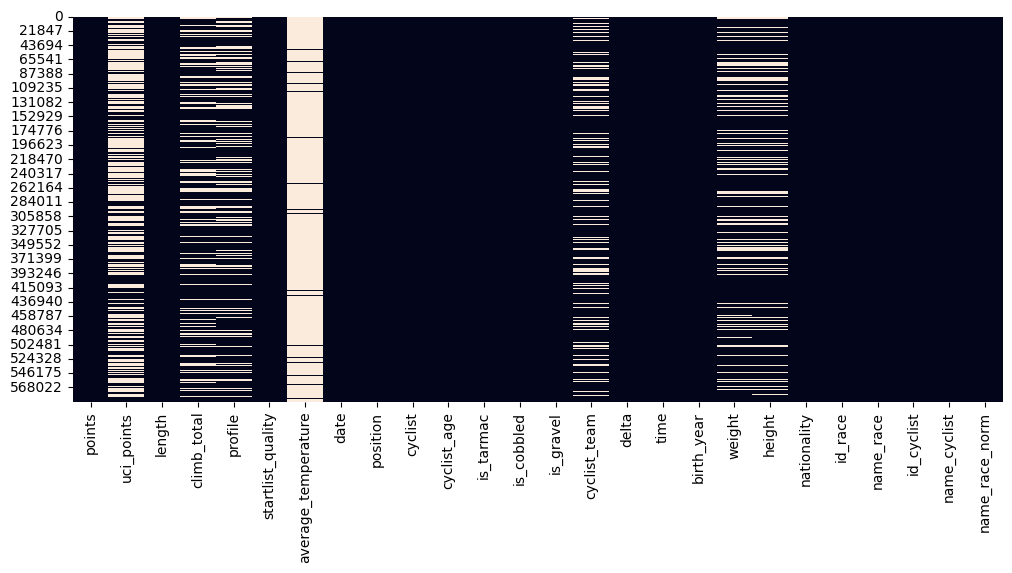

In [59]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

As can be seen from the map we have some missing values on these features:
- `uci_points`
- `climb_total`
- `profile`
- `average_temperature`
- `cyclist_team`
- `weight`
- `height`

Let's see again the correlation matrix

In [60]:
"""Dataset understanding utilities."""
from typing import Dict
import pandas


def correlations(dataset: pandas.DataFrame) -> pandas.DataFrame:
    correlations_dictionary = {
        correlation_type: dataset.corr(numeric_only=True, method=correlation_type)
        for correlation_type in ("kendall", "pearson", "spearman")
    }
    for i, k in enumerate(correlations_dictionary.keys()):
        correlations_dictionary[k].loc[:, "correlation_type"] = k
    correlations_matrix = pandas.concat(correlations_dictionary.values())

    return correlations_matrix

In [61]:
df_numerical_features = df_merged.dropna().select_dtypes(include=['number'])
normalized_dataset, normalization_scalers_dataset = center_and_scale(df_numerical_features)
correlations = correlations(normalized_dataset)
correlations

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,position,cyclist_age,delta,birth_year,weight,height,correlation_type
points,1.000000,0.860994,0.200637,0.044654,-0.040243,0.560150,0.151729,0.016371,0.049198,0.133532,-0.065519,0.085092,0.040916,kendall
uci_points,0.860994,1.000000,0.188210,0.042924,-0.037369,0.534801,0.066974,0.007763,0.043275,0.115837,-0.041739,0.072269,0.035921,kendall
length,0.200637,0.188210,1.000000,0.064639,-0.128981,0.035504,-0.097622,0.000370,0.000076,-0.062641,-0.014964,0.007348,0.002690,kendall
climb_total,0.044654,0.042924,0.064639,1.000000,0.584836,0.034792,-0.084943,-0.023128,0.004645,0.403906,-0.015898,-0.045566,-0.027229,kendall
profile,-0.040243,-0.037369,-0.128981,0.584836,1.000000,0.017621,-0.022638,-0.009198,0.004913,0.420424,-0.008978,-0.022062,-0.012471,kendall
startlist_quality,0.560150,0.534801,0.035504,0.034792,0.017621,1.000000,0.222601,0.054819,0.063040,0.097472,-0.066490,0.081323,0.040652,kendall
average_temperature,0.151729,0.066974,-0.097622,-0.084943,-0.022638,0.222601,1.000000,0.017471,0.025604,0.024801,-0.050242,0.046658,0.024332,kendall
position,0.016371,0.007763,0.000370,-0.023128,-0.009198,0.054819,0.017471,1.000000,0.016919,0.342360,-0.016646,0.157936,0.087734,kendall
cyclist_age,0.049198,0.043275,0.000076,0.004645,0.004913,0.063040,0.025604,0.016919,1.000000,0.014984,-0.957688,0.053042,-0.023453,kendall
delta,0.133532,0.115837,-0.062641,0.403906,0.420424,0.097472,0.024801,0.342360,0.014984,1.000000,-0.022803,0.130283,0.066714,kendall


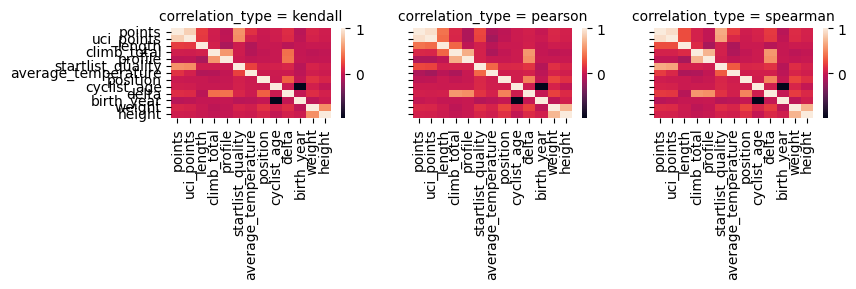

In [62]:
g = sns.FacetGrid(correlations, col="correlation_type")
g.map_dataframe(lambda data, color: sns.heatmap(data[data.columns[:-1]]))

<Axes: >

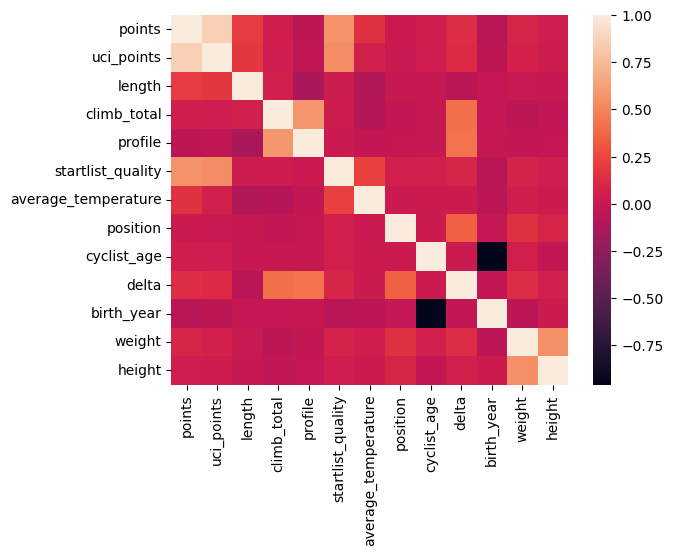

In [63]:
kendall_correlation = correlations.iloc[range(correlations.shape[1]-1), :].drop("correlation_type", axis="columns")
sns.heatmap(kendall_correlation)

In the data undertanding notebook, we saw that there are some features that are not so informative for our task. So in order to do an initial cleaning, we decide to delete `is_cobbled` and `is_gravel` since the value are all setted to false.

In [64]:
del df_merged['is_cobbled']
del df_merged['is_gravel']

Now we try to do some imputation in order to fill some missing values. Now we focus on `uci_points` feature. The latter give us another point of view to analyze the points obtained in a race, because takes into account even the difficulty of the race. By doing some research it seems that this points is obtained by linear combination of the points, the type of race and the position obtained. Therefore, we group the race by name and date and then we calculate uci_points_ratio, i.e. $\frac{\text{points}}{\text{uci\_points}}$

In [65]:
# Add the new column
df_merged['points_to_uci_ratio'] = df_merged.apply(
    lambda row: row['uci_points'] / row['points'] if pd.notnull(row['uci_points']) and row['uci_points'] != 0 else None,
    axis=1
)

df_merged[df_merged['position']==1][df_merged['name_race_norm']=='Tour de France'].dropna(subset=['points_to_uci_ratio'])[['points_to_uci_ratio', 'date']].sort_values(by='date').groupby('points_to_uci_ratio')['date'].agg(['count']).reset_index()

df_merged['date'] = pd.to_datetime(df_merged['date'])
race_dict = {}
for race_name, group in df_merged.groupby('name_race_norm'):
    group_sorted = group.sort_values(by='date')
    entries = []
    for ratio, ratio_group in group_sorted.groupby('points_to_uci_ratio'):
        min_date_row = ratio_group.iloc[0]
        max_date_row = ratio_group.iloc[-1]
        entries.append({"points_to_uci_ratio": ratio, "date": min_date_row['date'].strftime('%Y-%m-%d')})
        if min_date_row['date'] != max_date_row['date']:
            entries.append({"points_to_uci_ratio": ratio, "date": max_date_row['date'].strftime('%Y-%m-%d')})
    race_dict[race_name] = entries



/var/folders/m0/bthp7wg10n93z0r_crn31h400000gn/T/ipykernel_4818/1466651562.py:7: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_merged[df_merged['position']==1][df_merged['name_race_norm']=='Tour de France'].dropna(subset=['points_to_uci_ratio'])[['points_to_uci_ratio', 'date']].sort_values(by='date').groupby('points_to_uci_ratio')['date'].agg(['count']).reset_index()


In [66]:
keys = list(race_dict.keys())
for race in keys:
    if len(race_dict[race]) == 0:
        del race_dict[race]

In [67]:
df_merged['uci_points'].isna().sum()

338779

In [68]:
def get_closest_uci_points(row):
    if pd.notnull(row['uci_points']):
        return row['uci_points']
    if row['name_race_norm'] in race_dict:
        uci_points_list = race_dict[row['name_race_norm']]
        for i in range(len(uci_points_list) - 1):
            prev_date_in_dict = datetime.datetime.strptime(uci_points_list[i]["date"], "%Y-%m-%d")
            next_date_in_dict = datetime.datetime.strptime(uci_points_list[i + 1]["date"], "%Y-%m-%d")
            date_comparing = row['date']
            if date_comparing >= prev_date_in_dict and date_comparing <= next_date_in_dict:
                row['uci_points'] = uci_points_list[i]['points_to_uci_ratio'] * row['points']
    return row['uci_points']

df_merged['uci_points'] = df_merged.apply(get_closest_uci_points, axis=1)


In [69]:
df_merged['uci_points'].isna().sum()

335982

Now we focus on `weight` and `height` features. In order to fill some missing values, we try to fill them by using the average of them. Precisely, given a specific height we obtain the average of weight. We use this strategy even for the weight.

In [70]:
weight_by_height = df_merged.groupby('height')['weight'].mean()
height_by_weight = df_merged.groupby('weight')['height'].mean()

def fill_height(row, weight_by_height):
    if pd.isna(row['height']) or pd.isnull(row['height']):
        avg_weight = row['weight']
        closest_height = weight_by_height.sub(avg_weight).abs().idxmin() if pd.notna(avg_weight) else None
        return closest_height
    return row['height']

def fill_weight(row, height_by_weight):
    if pd.isna(row['weight']) or pd.isnull(row['weight']):
        weight = row['height']
        closest_weight = height_by_weight.sub(weight).abs().idxmin() if pd.notna(weight) else None
        return closest_weight
    return row['weight']

df_merged['height'] = df_merged.apply(fill_height, axis=1, weight_by_height= weight_by_height)
df_merged['weight'] = df_merged.apply(fill_weight, axis=1, height_by_weight= height_by_weight)

<Axes: >

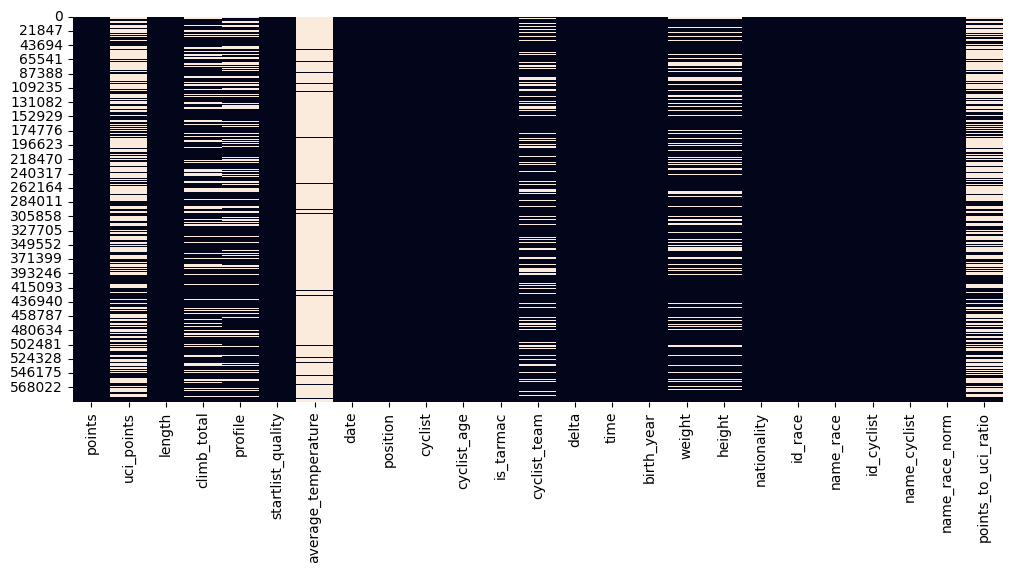

In [71]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

Finally we try to fill the missing values of `profile` and `climb_total`

In [72]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import OneHotEncoder

# Step 1: Separate rows with and without 'profile'
train_data = df_merged.dropna(subset=['profile'])  # Rows with known 'profile'
missing_data = df_merged[df_merged['profile'].isna()]    # Rows with missing 'profile'

# Step 2: Split training data into features and target
X = train_data[['length', 'climb_total']].fillna(0)  # Fill missing feature values with 0 (or use imputation)
y = train_data['profile'].astype(int)

# Step 3: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Train a classifier
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [73]:
y_pred = classifier.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test, y_pred)}")

Accuracy: 0.988373804267844
Classification Report:
              precision    recall  f1-score   support

           1       0.99      0.99      0.99     26381
           2       0.99      0.99      0.99     25393
           3       0.97      0.97      0.97     10227
           4       1.00      0.98      0.99      8592
           5       0.99      0.99      0.99     17742

    accuracy                           0.99     88335
   macro avg       0.99      0.99      0.99     88335
weighted avg       0.99      0.99      0.99     88335



In [74]:
for idx, row in missing_data.iterrows():
    if not (pd.isna(row['length']) or pd.isna(row['climb_total'])):
        # Prepare a single-row DataFrame for prediction
        X_single = pd.DataFrame([row[['length', 'climb_total']]])
        # Predict and update the missing value
        df_merged.loc[idx, 'profile'] = classifier.predict(X_single)[0]

<Axes: >

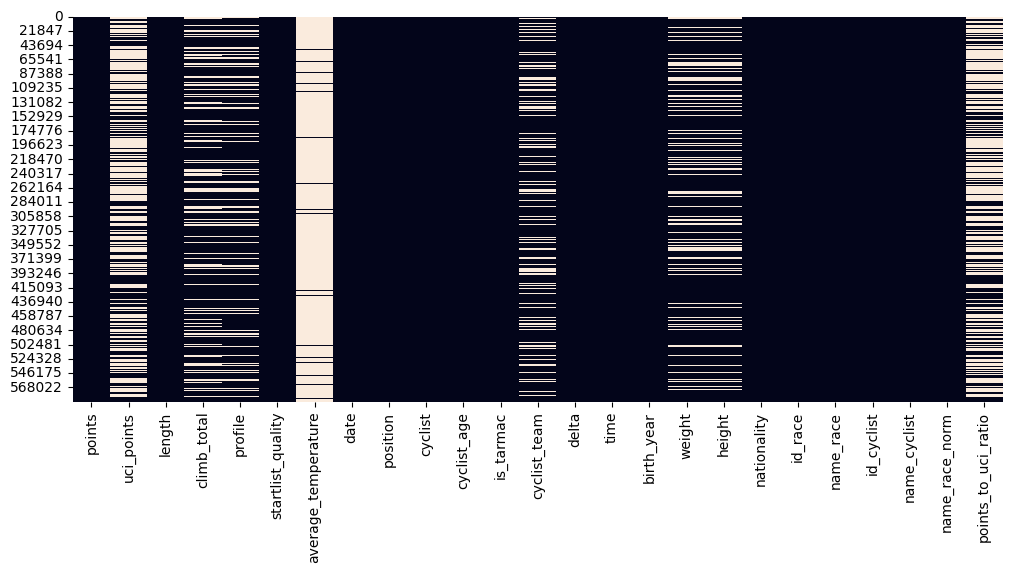

In [75]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

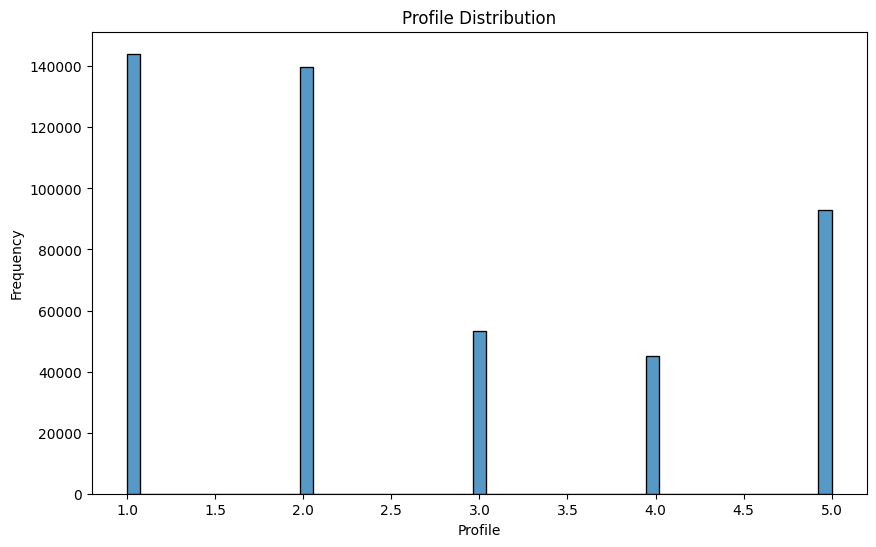

In [76]:
plt.figure(figsize=(10, 6))
sns.histplot(df_merged['profile'].dropna())
plt.title('Profile Distribution')
plt.xlabel('Profile')
plt.ylabel('Frequency')
plt.show()

The only two features that won't try to impute are `average_temperature` and `cyclist_teams`. The reason is that `average_temperature` there are too missing values and in our opinion we risks to add a lot of noise. On the other hand, for `cyclist_teams` feature we didn't find a strategy to fill them. The only way, in our opinion, is to apply the scraping.  

In data understanding notebook, we even see that `delta` feature isn't consistent with `position` feature. We firmly believe that the format of delta values isn't so specific because in the races even milliseconds are important. So decide to delete this feature. 

In [77]:
del df_merged['delta']

<Axes: >

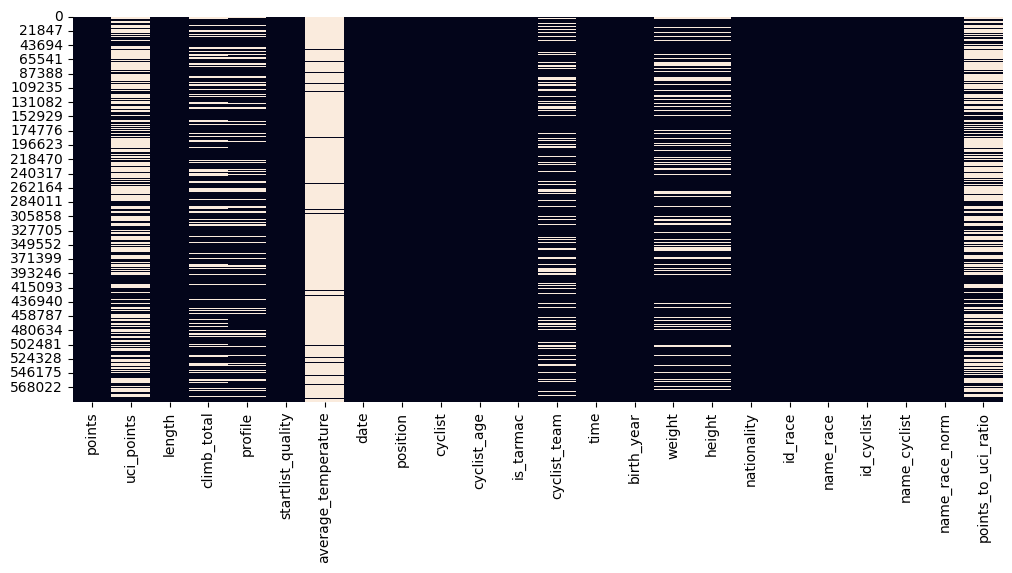

In [78]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

In [79]:
del df_merged['points_to_uci_ratio']

In [80]:

def add_nan_flags(df):
    """
    Adds a column `is_<feature>_nan` for each feature in the DataFrame
    that contains NaN values. The new column marks `True` if the row 
    has a NaN value in that feature, otherwise `False`.
    
    Parameters:
        df (pd.DataFrame): Input DataFrame.

    Returns:
        pd.DataFrame: DataFrame with additional NaN flag columns.
    """
    # Iterate through all columns in the DataFrame
    for col in df.columns:
        if df[col].isna().any():  # Check if the column contains NaN values
            # Add a new column indicating NaN presence for the feature
            df[f'is_{col}_nan'] = df[col].isna()
    return df


df_merged = add_nan_flags(df_merged)
df_merged

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,...,is_uci_points_nan,is_climb_total_nan,is_profile_nan,is_average_temperature_nan,is_cyclist_age_nan,is_cyclist_team_nan,is_birth_year_nan,is_weight_nan,is_height_nan,is_nationality_nan
0,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,0,sean-kelly,...,True,False,False,True,False,False,False,False,False,False
1,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,1,gerrie-knetemann,...,True,False,False,True,False,False,False,True,True,False
2,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,2,rene-bittinger,...,True,False,False,True,False,True,False,False,False,False
3,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,3,joseph-bruyere,...,True,False,False,True,False,False,False,True,True,False
4,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,4,sven-ake-nilsson,...,True,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589860,80.0,16.0,8400.0,60.0,1.0,878,NaN,2010-05-08,192,anders-lund-1,...,False,False,False,True,False,False,False,False,False,False
589861,80.0,16.0,8400.0,60.0,1.0,878,NaN,2010-05-08,193,andrea-masciarelli,...,False,False,False,True,False,True,False,False,False,False
589862,80.0,16.0,8400.0,60.0,1.0,878,NaN,2010-05-08,194,marco-corti,...,False,False,False,True,False,False,False,False,False,False
589863,80.0,16.0,8400.0,60.0,1.0,878,NaN,2010-05-08,195,robbie-mcewen,...,False,False,False,True,False,False,False,False,False,False


## Outlier detection

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,position,cyclist_age,birth_year,weight,height
0,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.533334,-1.682270,-1.879430,1.392699,0.047648
1,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.512675,-0.385465,-2.312855,NaN,NaN
2,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.492015,-1.163548,-2.052800,0.105351,-0.908599
3,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.471356,0.392619,-2.572911,NaN,NaN
4,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.450697,-0.385465,-2.312855,-0.860160,-1.227348


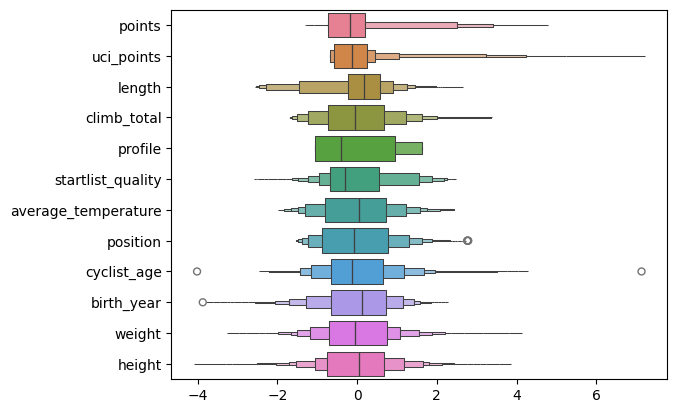

In [81]:
normalized_dataset, normalization_scalers_dataset = center_and_scale(df_merged)

sns.boxenplot(normalized_dataset, orient="h")
normalized_dataset.head()

/opt/homebrew/anaconda3/envs/ml/lib/python3.12/site-packages/matplotlib/axes/_axes.py:6973: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
/opt/homebrew/anaconda3/envs/ml/lib/python3.12/site-packages/matplotlib/axes/_axes.py:6974: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


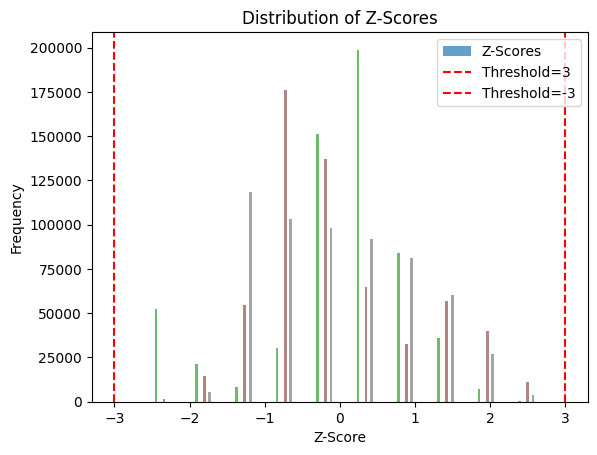

In [82]:
from scipy.stats import zscore

cop = df_merged.copy().select_dtypes(include="number")

z_scores = zscore(cop)
plt.hist(z_scores, alpha=0.7, label='Z-Scores')
plt.axvline(x=3, color='red', linestyle='--', label='Threshold=3')
plt.axvline(x=-3, color='red', linestyle='--', label='Threshold=-3')
plt.legend()
plt.title("Distribution of Z-Scores")
plt.xlabel("Z-Score")
plt.ylabel("Frequency")
plt.show()

In [83]:
outliers = (z_scores > 3).any(axis=1)
outliers_zscore = df_merged[outliers]
print("Outliers detected using Z-Score:")
print(outliers_zscore)

Outliers detected using Z-Score:
Empty DataFrame
Columns: [points, uci_points, length, climb_total, profile, startlist_quality, average_temperature, date, position, cyclist, cyclist_age, is_tarmac, cyclist_team, time, birth_year, weight, height, nationality, id_race, name_race, id_cyclist, name_cyclist, name_race_norm, is_points_nan, is_uci_points_nan, is_climb_total_nan, is_profile_nan, is_average_temperature_nan, is_cyclist_age_nan, is_cyclist_team_nan, is_birth_year_nan, is_weight_nan, is_height_nan, is_nationality_nan]
Index: []

[0 rows x 34 columns]


In [84]:
from sklearn.neighbors import LocalOutlierFactor

# Initialize Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20)
outlier_labels = lof.fit_predict(cop.fillna(0)) 

# Extract outliers
outliers_knn = cop[outlier_labels == -1]

print("Outliers detected using k-NN:")
print(outliers_knn)

Outliers detected using k-NN:
        points  uci_points    length  climb_total  profile  startlist_quality  \
245       80.0       100.0  196000.0       5575.0      5.0                821   
431       50.0         NaN    8100.0          NaN      NaN                804   
1105      50.0         NaN  189000.0          NaN      NaN                541   
1110      50.0         NaN  189000.0          NaN      NaN                541   
1113      50.0         NaN  189000.0          NaN      NaN                541   
...        ...         ...       ...          ...      ...                ...   
588844    50.0         NaN  184000.0          NaN      NaN                568   
588845    50.0         NaN  184000.0          NaN      NaN                568   
589448   275.0         NaN  273000.0          NaN      1.0                808   
589449   275.0         NaN  273000.0          NaN      1.0                808   
589458   275.0         NaN  273000.0          NaN      1.0                808  

In [85]:
from sklearn.ensemble import IsolationForest

# Initialize Isolation Forest
iso_forest = IsolationForest(contamination=0.05, random_state=42)
outlier_predictions = iso_forest.fit_predict(cop.fillna(0))  # -1 indicates an outlier

# Extract outliers
outliers_iso = cop[outlier_predictions == -1]

print("Outliers detected using Isolation Forest:")
print(outliers_iso)

Outliers detected using Isolation Forest:
        points  uci_points    length  climb_total  profile  startlist_quality  \
245       80.0       100.0  196000.0       5575.0      5.0                821   
546      100.0       120.0  192900.0       3743.0      3.0               1551   
638      100.0       120.0  192900.0       3743.0      3.0               1551   
650      100.0       120.0  192900.0       3743.0      3.0               1551   
652      100.0       120.0  192900.0       3743.0      3.0               1551   
...        ...         ...       ...          ...      ...                ...   
588237   225.0       400.0  231000.0       4156.0      2.0                800   
588240   225.0       400.0  231000.0       4156.0      2.0                800   
588242   225.0       400.0  231000.0       4156.0      2.0                800   
588246   225.0       400.0  231000.0       4156.0      2.0                800   
588248   225.0       400.0  231000.0       4156.0      2.0         

/opt/homebrew/anaconda3/envs/ml/lib/python3.12/site-packages/matplotlib_venn/layout/venn3/pairwise.py:103: UserWarning: Circle A has zero area.
  warnings.warn("Circle A has zero area.")


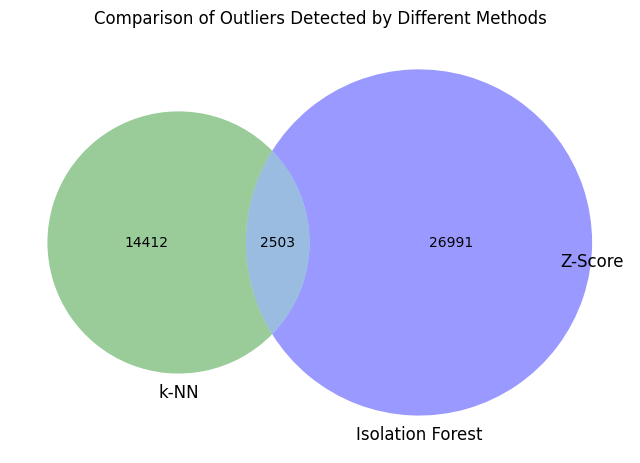

In [86]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

zscore_indices = set(outliers_zscore.index)
knn_indices = set(outliers_knn.index)
iso_indices = set(outliers_iso.index)

cop['outlier_zscore'] = cop.index.isin(zscore_indices).astype(int)
cop['outlier_knn'] = cop.index.isin(knn_indices).astype(int)
cop['outlier_iso'] = cop.index.isin(iso_indices).astype(int)
cop['any_outlier'] = cop[['outlier_zscore', 'outlier_knn', 'outlier_iso']].any(axis=1).astype(int)

plt.figure(figsize=(8, 6))
venn3([zscore_indices, knn_indices, iso_indices], ('Z-Score', 'k-NN', 'Isolation Forest'))
plt.title("Comparison of Outliers Detected by Different Methods")
plt.show()

In [87]:
cop

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,position,cyclist_age,birth_year,weight,height,outlier_zscore,outlier_knn,outlier_iso,any_outlier
0,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,0,22.0,1956.0,77.0,180.0,0,0,0,0
1,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1,27.0,1951.0,NaN,NaN,0,0,0,0
2,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,2,24.0,1954.0,69.0,174.0,0,0,0,0
3,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,3,30.0,1948.0,NaN,NaN,0,0,0,0
4,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,4,27.0,1951.0,63.0,172.0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589860,80.0,16.0,8400.0,60.0,1.0,878,NaN,192,25.0,1985.0,65.0,167.0,0,0,0,0
589861,80.0,16.0,8400.0,60.0,1.0,878,NaN,193,28.0,1982.0,61.0,173.0,0,0,0,0
589862,80.0,16.0,8400.0,60.0,1.0,878,NaN,194,24.0,1986.0,59.0,171.0,0,0,0,0
589863,80.0,16.0,8400.0,60.0,1.0,878,NaN,195,38.0,1972.0,67.0,171.0,0,0,0,0


In [88]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_result = pca.fit_transform(cop.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso']).fillna(0))

cop['pca1'] = pca_result[:, 0]
cop['pca2'] = pca_result[:, 1]


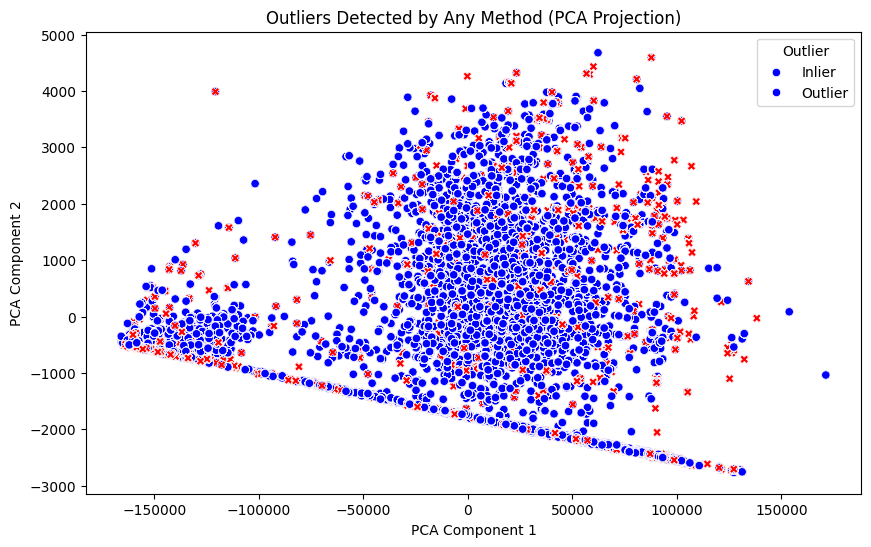

In [89]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cop, x='pca1', y='pca2', hue='any_outlier', style='any_outlier', palette={0: 'blue', 1: 'red'})
plt.title("Outliers Detected by Any Method (PCA Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Outlier", labels=["Inlier", "Outlier"])
plt.show()

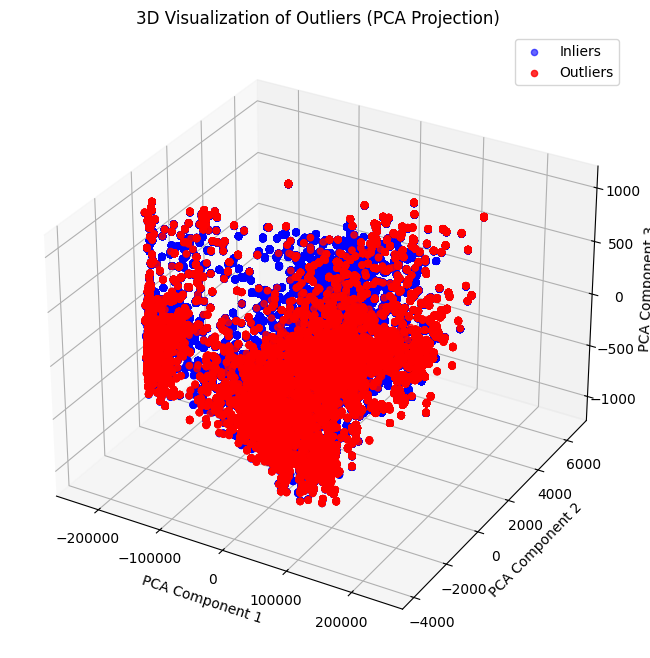

In [90]:
from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3)
pca_result = pca.fit_transform(cop.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso']).fillna(0))

cop['pca1'] = pca_result[:, 0]
cop['pca2'] = pca_result[:, 1]
cop['pca3'] = pca_result[:, 2]

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

inliers = cop[cop['any_outlier'] == 0]
outliers = cop[cop['any_outlier'] == 1]

ax.scatter(inliers['pca1'], inliers['pca2'], inliers['pca3'], c='blue', label='Inliers', alpha=0.6)
ax.scatter(outliers['pca1'], outliers['pca2'], outliers['pca3'], c='red', label='Outliers', alpha=0.8)

ax.set_title('3D Visualization of Outliers (PCA Projection)')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
ax.legend()
plt.show()

Let's for each algortihm what kind of outliers recognize


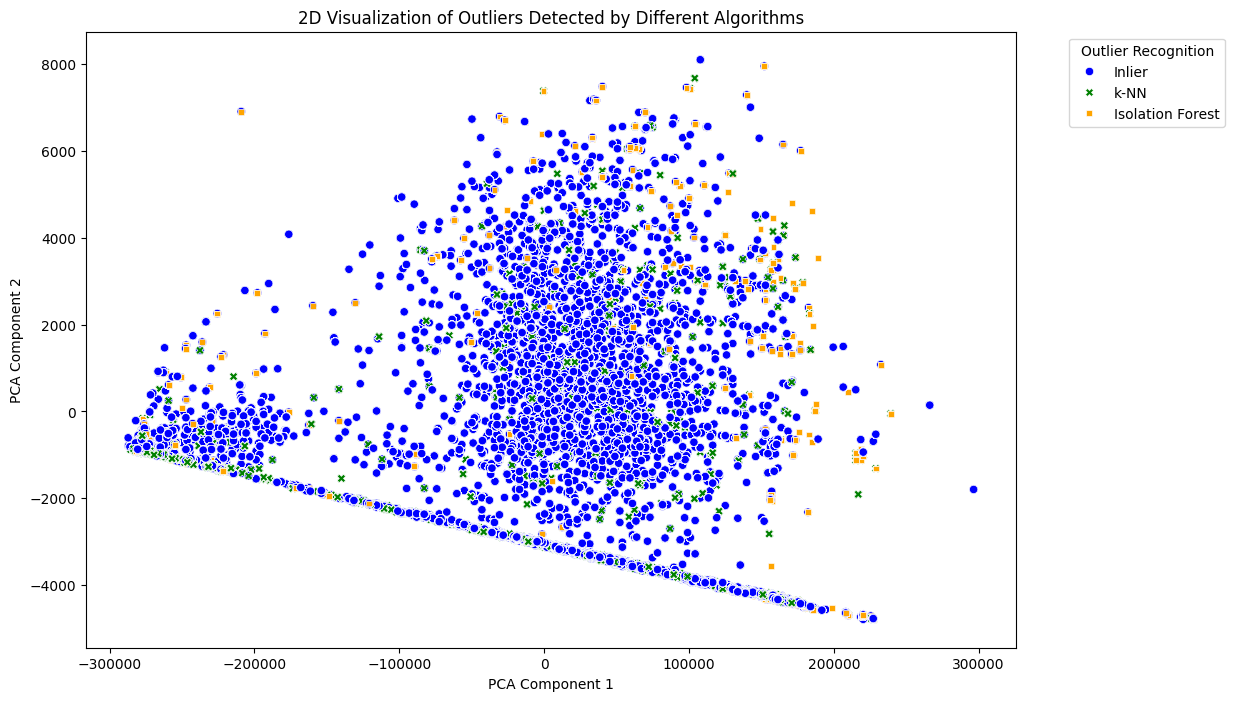

In [91]:
def get_outlier_label(row):
    if row['outlier_zscore']:
        return 'Z-Score'
    elif row['outlier_knn']:
        return 'k-NN'
    elif row['outlier_iso']:
        return 'Isolation Forest'
    return 'Inlier'

cop['outlier_zscore'] = cop.index.isin(zscore_indices).astype(int)
cop['outlier_knn'] = cop.index.isin(knn_indices).astype(int)
cop['outlier_iso'] = cop.index.isin(iso_indices).astype(int)

cop['outlier_label'] = cop.apply(get_outlier_label, axis=1)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(cop.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso', 'outlier_label']).fillna(0))
cop['pca1'] = pca_result[:, 0]
cop['pca2'] = pca_result[:, 1]

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=cop,
    x='pca1', y='pca2',
    hue='outlier_label',
    palette={'Inlier': 'blue', 'Z-Score': 'red', 'k-NN': 'green', 'Isolation Forest': 'orange'},
    style='outlier_label'
)
plt.title('2D Visualization of Outliers Detected by Different Algorithms')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Outlier Recognition', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

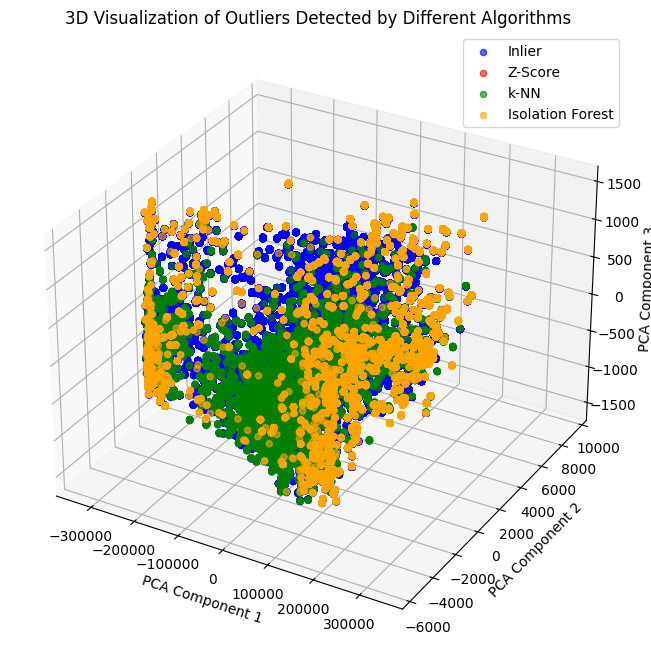

In [92]:
pca = PCA(n_components=3)
pca_result = pca.fit_transform(cop.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso', 'outlier_label']).fillna(0))
cop['pca1'] = pca_result[:, 0]
cop['pca2'] = pca_result[:, 1]
cop['pca3'] = pca_result[:, 2]

# Prepare the figure
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot points based on their outlier labels
colors = {'Inlier': 'blue', 'Z-Score': 'red', 'k-NN': 'green', 'Isolation Forest': 'orange'}
for label, color in colors.items():
    subset = cop[cop['outlier_label'] == label]
    ax.scatter(subset['pca1'], subset['pca2'], subset['pca3'], c=color, label=label, alpha=0.6)

# Add labels and legend
ax.set_title('3D Visualization of Outliers Detected by Different Algorithms')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
ax.legend()
plt.show()

Drop all outliers

In [93]:
df_merged['outlier_zscore'] = df_merged.index.isin(zscore_indices).astype(int)
df_merged['outlier_knn'] = df_merged.index.isin(knn_indices).astype(int)
df_merged['outlier_iso'] = df_merged.index.isin(iso_indices).astype(int)

df_merged['is_outlier'] = (
    df_merged['outlier_zscore'] | 
    df_merged['outlier_knn'] | 
    df_merged['outlier_iso']
).astype(bool)


df_cleaned = df_merged[~df_merged['is_outlier']].copy()

df_cleaned.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso', 'is_outlier'], inplace=True)

print("Shape of the original dataset:", df_merged.shape)
print("Shape of the cleaned dataset:", df_cleaned.shape)

Shape of the original dataset: (589865, 38)
Shape of the cleaned dataset: (545959, 34)


In [94]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 545959 entries, 0 to 589864
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   points                      545516 non-null  float64       
 1   uci_points                  240196 non-null  float64       
 2   length                      545959 non-null  float64       
 3   climb_total                 412095 non-null  float64       
 4   profile                     443196 non-null  float64       
 5   startlist_quality           545959 non-null  int64         
 6   average_temperature         22840 non-null   float64       
 7   date                        545959 non-null  datetime64[ns]
 8   position                    545959 non-null  int64         
 9   cyclist                     545959 non-null  object        
 10  cyclist_age                 545959 non-null  float64       
 11  is_tarmac                   545959 non-

## Feature Engeneering

In [95]:
del df_cleaned['birth_year']

In [96]:
df_cleaned['length'] = df_cleaned['length'] / 1000
df_cleaned['climb_total'] = df_cleaned['climb_total'] / 1000

In [97]:
df_cleaned[['length', 'climb_total']]

,length,climb_total
0,162.0,1.101
1,162.0,1.101
2,162.0,1.101
3,162.0,1.101
4,162.0,1.101
...,...,...
589860,8.4,0.060
589861,8.4,0.060
589862,8.4,0.060
589863,8.4,0.060


In [98]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 545959 entries, 0 to 589864
Data columns (total 33 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   points                      545516 non-null  float64       
 1   uci_points                  240196 non-null  float64       
 2   length                      545959 non-null  float64       
 3   climb_total                 412095 non-null  float64       
 4   profile                     443196 non-null  float64       
 5   startlist_quality           545959 non-null  int64         
 6   average_temperature         22840 non-null   float64       
 7   date                        545959 non-null  datetime64[ns]
 8   position                    545959 non-null  int64         
 9   cyclist                     545959 non-null  object        
 10  cyclist_age                 545959 non-null  float64       
 11  is_tarmac                   545959 non-

In [99]:
bins = [18, 25, 35, 100]  # Age ranges: 18-25, 26-35, 36+
labels = ['18-25', '26-35', '36+']

# Create the 'age_group' column by binning 'cyclist_age'
df_cleaned['age_group'] = pd.cut(df_cleaned['cyclist_age'], bins=bins, labels=labels, right=True)

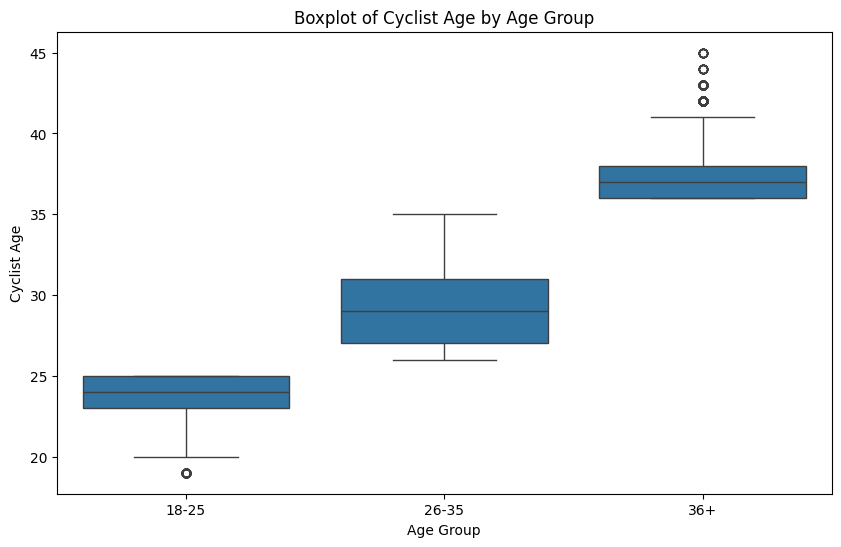

In [100]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_cleaned, x='age_group', y='cyclist_age')
plt.title('Boxplot of Cyclist Age by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Cyclist Age')
plt.show()

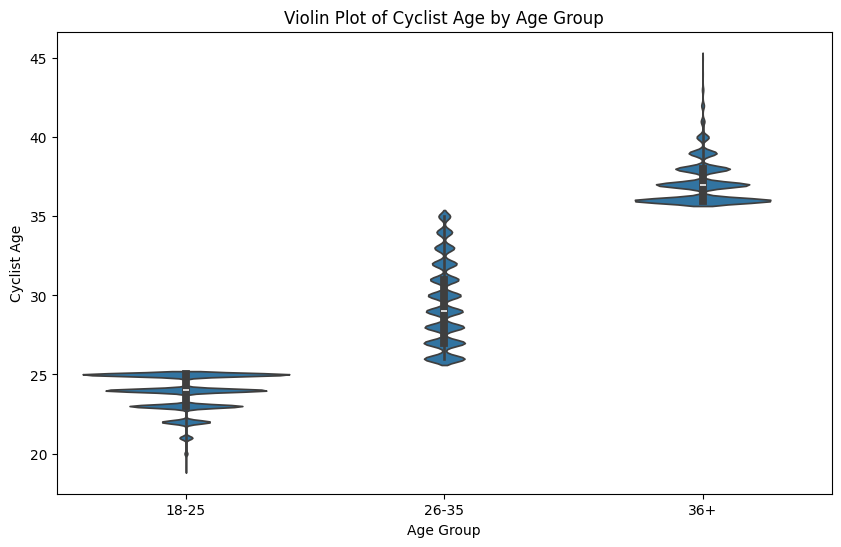

In [101]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_cleaned, x='age_group', y='cyclist_age')
plt.title('Violin Plot of Cyclist Age by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Cyclist Age')
plt.show()

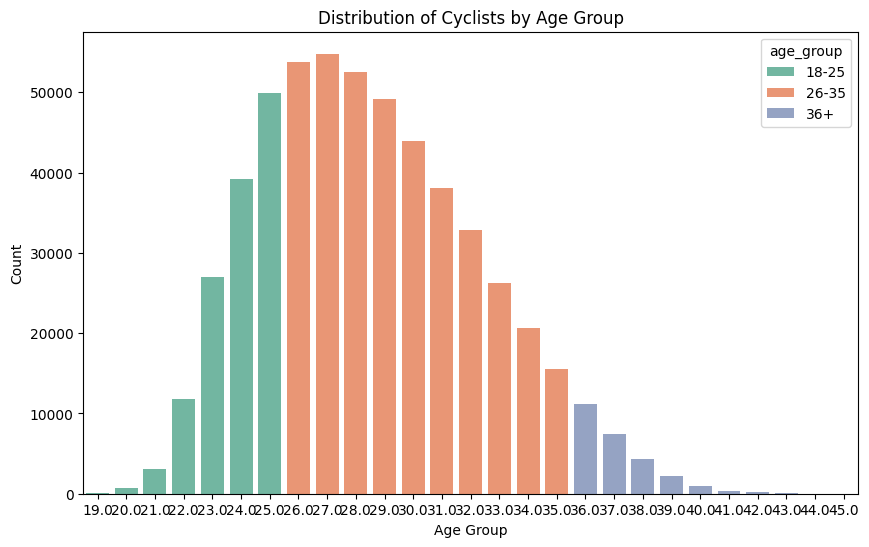

In [102]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df_cleaned, x='cyclist_age', palette='Set2', hue="age_group")
plt.title('Distribution of Cyclists by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.show()

In [103]:
# Dictionary for country-to-region mapping
country_to_region = {
    # Europe
    'Albania': 'Europe', 'Austria': 'Europe', 'Belarus': 'Europe', 'Belgium': 'Europe',
    'Bulgaria': 'Europe', 'Croatia': 'Europe', 'Czech Republic': 'Europe', 'Denmark': 'Europe',
    'Estonia': 'Europe', 'Finland': 'Europe', 'France': 'Europe', 'Germany': 'Europe',
    'Great Britain': 'Europe', 'Greece': 'Europe', 'Hungary': 'Europe', 'Ireland': 'Europe',
    'Italy': 'Europe', 'Latvia': 'Europe', 'Lithuania': 'Europe', 'Luxembourg': 'Europe',
    'Moldova': 'Europe', 'Monaco': 'Europe', 'Netherlands': 'Europe', 'Norway': 'Europe',
    'Poland': 'Europe', 'Portugal': 'Europe', 'Romania': 'Europe', 'Russia': 'Europe',
    'Serbia': 'Europe', 'Slovakia': 'Europe', 'Slovenia': 'Europe', 'Spain': 'Europe',
    'Sweden': 'Europe', 'Switzerland': 'Europe', 'Ukraine': 'Europe',

    # Asia
    'Azerbaijan': 'Asia', 'China': 'Asia', 'Iran': 'Asia', 'Israel': 'Asia', 'Japan': 'Asia',
    'Kazakhstan': 'Asia', 'Taiwan': 'Asia', 'Uzbekistan': 'Asia',

    # Africa
    'Algeria': 'Africa', 'Eritrea': 'Africa', 'Ethiopia': 'Africa', 'Morocco': 'Africa',
    'Namibia': 'Africa', 'Rwanda': 'Africa', 'South Africa': 'Africa',

    # North America
    'Canada': 'North America', 'Costa Rica': 'North America', 'Guatemala': 'North America',
    'Mexico': 'North America', 'Panama': 'North America', 'Puerto Rico': 'North America',
    'United States': 'North America',

    # South America
    'Argentina': 'South America', 'Brazil': 'South America', 'Chile': 'South America',
    'Colombia': 'South America', 'Ecuador': 'South America', 'Uruguay': 'South America',
    'Venezuela': 'South America',

    # Oceania
    'Australia': 'Oceania', 'New Zealand': 'Oceania'
}

# Map countries to regions in the DataFrame
df_cleaned['region'] = df_cleaned['nationality'].map(country_to_region)

# Check the regional distribution
region_summary = df_cleaned['region'].value_counts()
print(region_summary)

Europe           476180
Oceania           21339
North America     19770
South America     16675
Asia               7302
Africa             4608
Name: region, dtype: int64


In [104]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 545959 entries, 0 to 589864
Data columns (total 35 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   points                      545516 non-null  float64       
 1   uci_points                  240196 non-null  float64       
 2   length                      545959 non-null  float64       
 3   climb_total                 412095 non-null  float64       
 4   profile                     443196 non-null  float64       
 5   startlist_quality           545959 non-null  int64         
 6   average_temperature         22840 non-null   float64       
 7   date                        545959 non-null  datetime64[ns]
 8   position                    545959 non-null  int64         
 9   cyclist                     545959 non-null  object        
 10  cyclist_age                 545959 non-null  float64       
 11  is_tarmac                   545959 non-

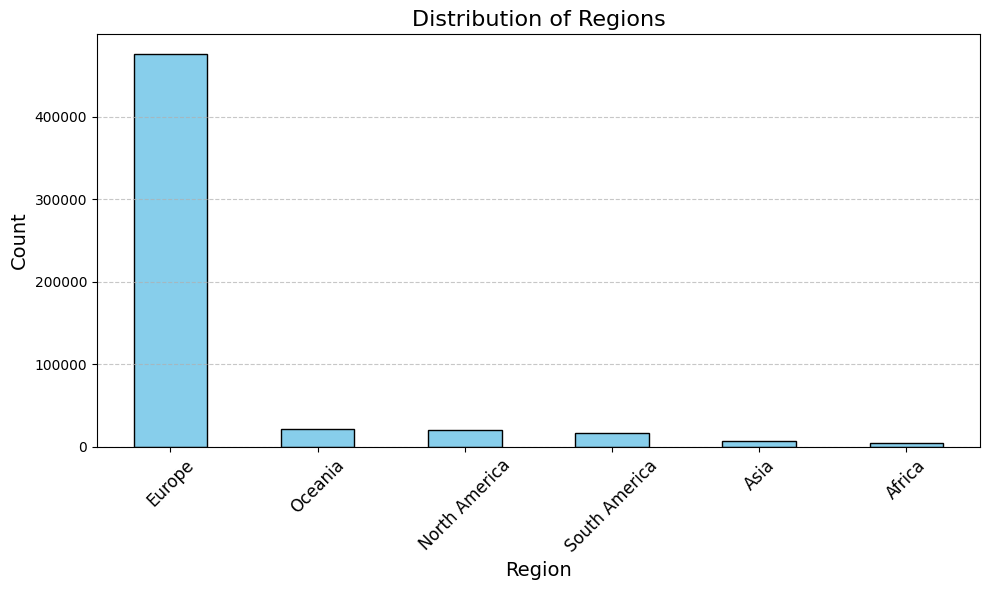

In [105]:
# Count the number of occurrences in each region
region_distribution = df_cleaned['region'].value_counts()

# Plot the distribution
plt.figure(figsize=(10, 6))
region_distribution.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('Region', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.title('Distribution of Regions', fontsize=16)
plt.xticks(rotation=45, fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

In [107]:
df_cleaned.to_csv('../dataset/cleaned.csv', index=False)